# WindDesk: January 2026 wind forecast error analysis

This notebook supports the WindDesk pilot. It uses the **same validated snapshot and the same
domain functions** as the API (`backend/app/domain`), so every number here matches the portal.

Questions:
1. Is the data complete and well-formed?
2. How accurate was the forecast available at day-ahead gate closure?
3. Is the error systematic (bias) or random, and when is it largest?
4. How quickly does accuracy decay with lead time, and what does waiting for a later run buy?
5. Is the empirical P10–P90 band calibrated?

Sign convention: `error = forecast − actual` (positive = over-forecast). Run from the repo root
with the backend environment: `uv run --project backend --group analysis jupyter nbconvert --execute`.

In [1]:
import sys
from datetime import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "backend").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "backend"))

from app.data.snapshot import load_snapshot
from app.domain import reports, uncertainty
from app.domain.alignment import hourly_actuals
from app.domain.market import UK_TZ, decision_dates
from app.domain.metrics import summarize

plt.rcParams.update({
    "figure.figsize": (10, 3.6), "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
})
FORECAST, ACTUAL, LATER, UNDER, OVER = "#1aa0bf", "#c98500", "#9085e9", "#3987e5", "#e66767"

snap = load_snapshot(ROOT / "backend" / "data" / "snapshot")
hourly = hourly_actuals(snap.actuals)
print("snapshot", snap.version, "created", snap.manifest["created_at"])
print("actual half-hours:", len(snap.actuals), "| forecast rows:", len(snap.forecasts),
      "| runs:", snap.forecasts.publish_time.nunique())

snapshot jan2026-2a1d75fda6 created 2026-10-23T16:17:18Z
actual half-hours: 1488 | forecast rows: 17864 | runs: 256


## 1. Data quality
The ingestion validation report is stored in the snapshot manifest.

In [2]:
v = snap.manifest["validation"]
quality = pd.DataFrame({
    "actuals (FUELHH WIND)": {k: v["actuals"][k] for k in [
        "rows_received", "rows_clean", "expected_periods", "duplicate_rows_identical",
        "duplicate_rows_conflicting", "invalid_generation_rows_dropped",
        "settlement_period_mismatches"]} | {"missing_periods": len(v["actuals"]["missing_periods"])},
    "forecasts (WINDFOR)": {k: v["forecasts"][k] for k in [
        "rows_received", "rows_clean", "runs", "duplicate_rows_identical",
        "duplicate_rows_conflicting", "invalid_generation_rows_dropped", "non_future_rows",
        "min_runs_per_target_hour"]},
})
quality

,actuals (FUELHH WIND),forecasts (WINDFOR)
rows_received,1488.0,19272.0
rows_clean,1488.0,17864.0
expected_periods,1488.0,NaN
duplicate_rows_identical,0.0,0.0
duplicate_rows_conflicting,0.0,0.0
invalid_generation_rows_dropped,0.0,0.0
settlement_period_mismatches,0.0,NaN
missing_periods,0.0,NaN
runs,NaN,256.0
non_future_rows,NaN,3577.0


In [3]:
runs = pd.Series(snap.forecasts.publish_time.unique())
schedule = runs.dt.tz_convert(UK_TZ).dt.strftime("%H:%M").value_counts().sort_index()
print("Publication times (UK local) and number of days observed:")
print(schedule.to_string())
print("Off-schedule runs:", [t.isoformat() for t in runs if t.strftime("%H:%M") not in
      {s.strftime("%H:%M") for s in reports.scheduled_publish_slots(snap.forecasts)}])

Publication times (UK local) and number of days observed:
02:30    32
04:30    32
07:30    32
09:30    32
11:30    31
12:25     1
15:30    32
18:30    32
22:30    32


Off-schedule runs: ['2026-01-15T12:25:00+00:00']


**Observations.** No gaps, no duplicates, no invalid values. WINDFOR runs come out
8 times a day; one run on 15 Jan was late (12:25 instead of 11:30). Elexon's endpoint description
lists 03:30, 05:30, …, 23:30. The January `publishTime` values are one hour earlier, which matches a
schedule fixed in CET. A July 2025 check showed 03:30Z etc. WindDesk uses `publishTime` as the
availability time, as the brief defines it.

## 2. Accuracy of the forecast available at the gate

In [4]:
GATES = {"EPEX 60-min (09:20)": time(9, 20), "N2EX (09:50)": time(9, 50),
         "EPEX 30-min (15:30)": time(15, 30)}
aligned = {name: reports.align_decisions(snap.forecasts, hourly, decision_dates(), g)
           for name, g in GATES.items()}
cols = ["n_matched", "mae_mw", "rmse_mw", "bias_mw", "wape_pct", "p50_abs_error_mw",
        "p90_abs_error_mw", "p99_abs_error_mw", "max_abs_error_mw", "correlation",
        "energy_error_mwh"]
table = pd.DataFrame({n: summarize(a).to_dict() for n, a in aligned.items()}).T[cols]
table.astype(float).round(1).assign(correlation=table["correlation"].astype(float).round(3))

,n_matched,mae_mw,rmse_mw,bias_mw,wape_pct,p50_abs_error_mw,p90_abs_error_mw,p99_abs_error_mw,max_abs_error_mw,correlation,energy_error_mwh
EPEX 60-min (09:20),744.0,2038.9,2504.8,1747.9,18.1,1671.0,4097.9,6261.3,6870.0,0.931,1300428.0
N2EX (09:50),744.0,2013.0,2505.9,1729.9,17.8,1608.0,4143.8,6261.3,6833.0,0.931,1287069.0
EPEX 30-min (15:30),744.0,1873.5,2326.6,1709.2,16.6,1608.2,3780.6,6119.8,7073.0,0.956,1271644.0


Over-forecast hours: 84.3%  |  days with positive bias: 28/31
Total energy error: 1,287 GWh (15.3% of actual)


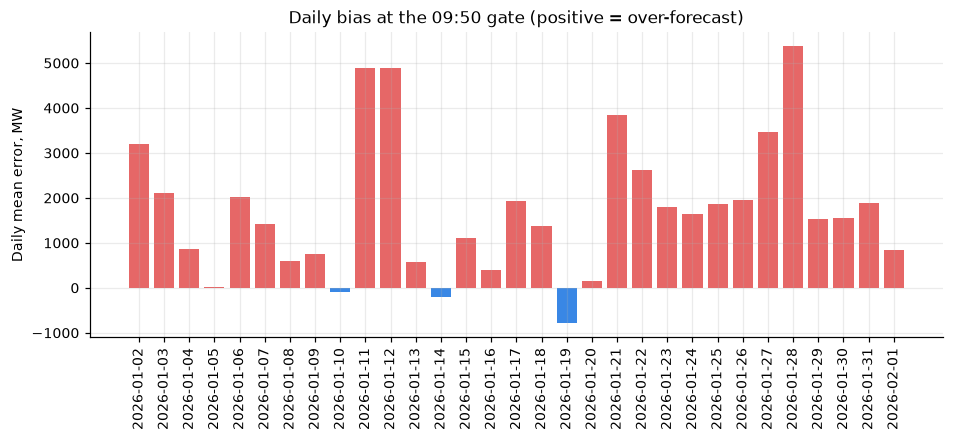

In [5]:
base = aligned["N2EX (09:50)"]
matched = base.dropna(subset=["error_mw"])
over_share = (matched.error_mw > 0).mean() * 100
daily = matched.groupby("delivery_date").agg(mae=("error_mw", lambda e: e.abs().mean()),
                                             bias=("error_mw", "mean"),
                                             energy_error_gwh=("error_mw", lambda e: e.sum() / 1000))
print(f"Over-forecast hours: {over_share:.1f}%  |  days with positive bias: "
      f"{(daily.bias > 0).sum()}/{len(daily)}")
print(f"Total energy error: {matched.error_mw.sum() / 1000:,.0f} GWh "
      f"({100 * matched.error_mw.sum() / matched.actual_mw.sum():.1f}% of actual)")

fig, ax = plt.subplots()
ax.bar(daily.index.astype(str), daily.bias, color=[OVER if b > 0 else UNDER for b in daily.bias])
ax.set_ylabel("Daily mean error, MW"); ax.set_title("Daily bias at the 09:50 gate (positive = over-forecast)")
ax.tick_params(axis="x", rotation=90); plt.show()

**Finding.** The error is **mostly systematic**: 84% of hours and 28 of 31 days were
over-forecast, and the mean bias (+1.7 GW) is close to the MAE (2.0 GW). A desk that plans on the raw forecast
consistently expects more wind than arrives, so it under-procures and is exposed to short
imbalance positions.

## 3. When is the error largest?

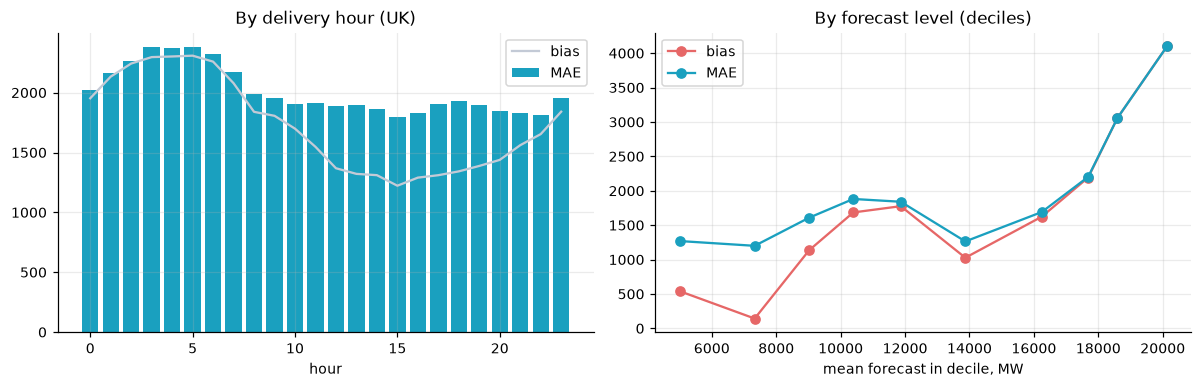

,forecast_mw,bias,mae
forecast_decile,,,
0,5001.0,541.0,1270.0
1,7330.0,143.0,1200.0
2,9022.0,1136.0,1609.0
3,10393.0,1686.0,1881.0
4,11867.0,1777.0,1841.0
5,13871.0,1027.0,1264.0
6,16245.0,1624.0,1692.0
7,17685.0,2193.0,2203.0
8,18595.0,3059.0,3059.0


In [6]:
m = matched.copy()
m["hour_uk"] = m.index.tz_convert(UK_TZ).hour
m["forecast_decile"] = pd.qcut(m.forecast_mw, 10, labels=False)
by_hour = m.groupby("hour_uk").error_mw.agg(mae=lambda e: e.abs().mean(), bias="mean")
by_level = m.groupby("forecast_decile").agg(forecast_mw=("forecast_mw", "mean"),
                                            bias=("error_mw", "mean"),
                                            mae=("error_mw", lambda e: e.abs().mean()))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].bar(by_hour.index, by_hour.mae, color=FORECAST, label="MAE")
axes[0].plot(by_hour.index, by_hour.bias, color="#c3cad6", label="bias")
axes[0].set_title("By delivery hour (UK)"); axes[0].set_xlabel("hour"); axes[0].legend()
axes[1].plot(by_level.forecast_mw, by_level.bias, "o-", color=OVER, label="bias")
axes[1].plot(by_level.forecast_mw, by_level.mae, "o-", color=FORECAST, label="MAE")
axes[1].set_title("By forecast level (deciles)"); axes[1].set_xlabel("mean forecast in decile, MW")
axes[1].legend(); plt.tight_layout(); plt.show()
by_level.round(0)

**Finding.** Bias is not uniform. It is a few hundred MW in the lowest forecast deciles and
**2.2–4.1 GW in the top three deciles** (forecasts of about 17.7 GW and above), so high-wind
forecasts miss the most.
One possible cause is curtailment and constraint actions, which lower metered output when wind is
high. The two supplied datasets cannot confirm this, so it is a hypothesis for the next phase. At a
fixed gate, hour of day and lead time move together, so the hourly pattern partly reflects lead
time.

## 4. Accuracy versus lead time, and the value of waiting

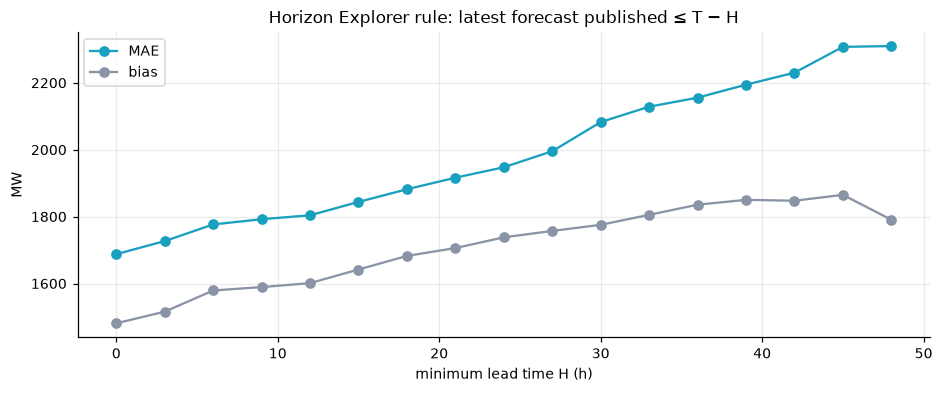

min_lead_h,0,3,6,9,12,15,18,21,24,27,30,33,36,39,42,45,48
mae_mw,1688.0,1727.0,1777.0,1792.0,1804.0,1844.0,1882.0,1916.0,1948.0,1996.0,2083.0,2129.0,2156.0,2194.0,2230.0,2308.0,2310.0
bias_mw,1481.0,1516.0,1579.0,1589.0,1601.0,1642.0,1683.0,1706.0,1738.0,1757.0,1776.0,1805.0,1836.0,1850.0,1848.0,1865.0,1791.0
n,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,744.0,682.0,589.0


In [7]:
start, end = pd.Timestamp("2026-01-02", tz="UTC"), pd.Timestamp("2026-02-02", tz="UTC")
from app.domain.alignment import align, select_at_horizon
slots = pd.date_range(start, end, freq="h", inclusive="left")
curve = []
for h in range(0, 49, 3):
    a = align(slots, select_at_horizon(snap.forecasts, start, end, h), hourly)
    s = summarize(a)
    curve.append({"min_lead_h": h, "mae_mw": s.mae_mw, "bias_mw": s.bias_mw, "n": s.n_matched})
curve = pd.DataFrame(curve).set_index("min_lead_h")
fig, ax = plt.subplots()
ax.plot(curve.index, curve.mae_mw, "o-", color=FORECAST, label="MAE")
ax.plot(curve.index, curve.bias_mw, "o-", color="#8a94a6", label="bias")
ax.set_xlabel("minimum lead time H (h)"); ax.set_ylabel("MW"); ax.legend()
ax.set_title("Horizon Explorer rule: latest forecast published ≤ T − H"); plt.show()
curve.round(0).T

In [8]:
vint = reports.vintage_comparison(snap.forecasts, hourly, sorted(base.delivery_date.unique()), time(9, 50))
vt = pd.DataFrame([{ "slot (D-1, UK)": v["slot"], "available at 09:50": v["available_at_gate"],
                     "MAE": v["metrics"].mae_mw, "bias": v["metrics"].bias_mw, "days": v["n_days"]}
                   for v in vint]).set_index("slot (D-1, UK)")
vt.round(0)

,available at 09:50,MAE,bias,days
"slot (D-1, UK)",,,,
02:30,True,2073.0,1735.0,31
04:30,True,2016.0,1671.0,31
07:30,True,2039.0,1748.0,31
09:30,True,2013.0,1730.0,31
11:30,False,1904.0,1692.0,31
15:30,False,1873.0,1709.0,31
18:30,False,1874.0,1692.0,31
22:30,False,1825.0,1603.0,31


**Finding.** Accuracy improves as lead time shortens, but slowly: MAE falls from about
2.3 GW at 48 h to about 1.7 GW for the freshest forecast. (Fewer hours are matched at H ≥ 45 h
because runs reach only about 66 h ahead and the snapshot holds only runs that can target the
January-decision delivery days.) Within the D−1 runs, the
22:30 run is about 9% better (MAE) than the 09:30 run that the N2EX gate allows. Most of the error
is bias, which waiting does not remove. **Correcting the bias is worth more than waiting.**

## 4b. Did each run actually update the forecast?

In [9]:
from app.domain.alignment import genuine_predictions
g = genuine_predictions(snap.forecasts)
by_run = {p: grp.set_index("start_time").generation_mw for p, grp in g.groupby("publish_time")}
order = sorted(by_run)
repeats = []
for a, b in zip(order, order[1:]):
    common = by_run[a].index.intersection(by_run[b].index)
    if len(common) and (by_run[a][common] == by_run[b][common]).all():
        repeats.append({"run": a.strftime("%d %b %H:%M"), "repeated by": b.strftime("%d %b %H:%M"),
                        "common target hours": len(common)})
print(f"{len(repeats)} of {len(order) - 1} consecutive run pairs carried identical values")
pd.DataFrame(repeats)

8 of 255 consecutive run pairs carried identical values


,run,repeated by,common target hours
0,08 Jan 02:30,08 Jan 04:30,65
1,08 Jan 15:30,08 Jan 18:30,51
2,09 Jan 07:30,09 Jan 09:30,60
3,26 Jan 18:30,26 Jan 22:30,47
4,26 Jan 22:30,27 Jan 02:30,43
5,27 Jan 02:30,27 Jan 04:30,65
6,27 Jan 04:30,27 Jan 07:30,62
7,27 Jan 07:30,27 Jan 09:30,60


**Finding: a stale feed before the worst day.** Repeated runs are rare (8 of 255 pairs).
Five of them form one streak, 26 Jan 18:30 → 27 Jan 09:30. The forecast selected at the 09:50
gate for **28 Jan**, January's worst delivery day (MAE 5.4 GW), had therefore not changed for
15 hours. The first run after the gate (11:30) cut that day's forecast energy by about 57 GWh.
WindDesk flags this case on the Day-Ahead Brief as a *stale feed* warning.

## 5. Alignment sensitivity
The primary comparison is the hourly mean of the two half-hours. As a check, we use the first half-hour only.

In [10]:
first_half = (base.forecast_mw - base.actual_first_half_mw).abs().mean()
print(f"MAE hourly-mean alignment:   {matched.error_mw.abs().mean():8.1f} MW")
print(f"MAE first-half-hour only:    {first_half:8.1f} MW")

MAE hourly-mean alignment:     2013.0 MW
MAE first-half-hour only:      1995.6 MW


Conclusions do not depend on the alignment choice (difference under 1%).

## 6. Is the P10–P90 band calibrated?

In [11]:
pool = uncertainty.error_pool(base)
cov = uncertainty.evaluate_coverage(base, pool)
print(f"Held-out coverage: {cov['coverage_pct']:.1f}% (nominal {cov['nominal_pct']:.0f}%) over {cov['n_evaluated']} hours")
pd.DataFrame(cov["by_bucket"]).set_index("label")[["n_evaluated", "coverage_pct"]].round(1)

Held-out coverage: 76.7% (nominal 80%) over 744 hours


,n_evaluated,coverage_pct
label,,
12–18 h,124,76.6
18–24 h,186,77.4
24–30 h,186,76.9
30–36 h,186,76.9
36–42 h,62,74.2


**Finding.** Leave-one-day-out coverage is about 77%, slightly below the nominal 80%.
This is reasonable for one month of autocorrelated errors. The band is shifted below the forecast
because it carries the systematic bias.

## Summary for the desk
* The gate-time forecast over-predicted wind in most January hours. Mean bias was about +1.7 GW
  and MAE about 2.0 GW.
* Error grows with forecast level, so high-wind days carry the most procurement risk.
* Waiting for later runs helps only slightly; correcting the bias would help far more.
* The empirical band is close to calibrated and is a reasonable range to plan against.

*Limitations:* national wind only, one month of data, no demand/price/curtailment data. Wind
forecast error is not procurement error.